# 56 — De-leakage curves for pairwise / small-group comparisons, each on its own common set

nb52 drew one EF@1% vs de-leakage curve per condition, each on that condition's own pockets. nb54 put all 10 conditions on one strict common set, which costs most of the pool (3,089 at `L0`, 30 at `L3<25`). This notebook does something in between. For each **comparison** below, only the conditions in that comparison are intersected, plus two references that every panel shows: `CCD + Bound pocket` (the default crystal-pocket condition) and `CCD + Patches` (random surface patches). Each panel compares like with like, without paying for requirements that don't matter to it. For example, `CCD vs Holo` doesn't need an apo structure or an AFDB model.

A pocket is in a comparison's set if it is `valid & in_library` in **every condition of that comparison, and in both references**. Both references cover every pocket whose ligand is in the CCD library (15533 of 15640), so adding them costs nothing. Everything else is unchanged from nb52: cross-dataset dedup, the nested 13-rung ladder, EF pooling, colours and labels. All scores come from the nb43/nb52 caches.

**Holo and Apo are subsets of AFDB by construction.** AHoJ was queried only for the 14,366 pockets with an AFDB-translated pocket (`ahoj_all_coverage_full.tsv` is exactly the AFDB manifest). So adding AFDB to a Holo or Apo comparison removes no pockets: `Holo vs AFDB` has the same set as `CCD vs Holo`.

In the comparison names, **"CCD" means `CCD + Bound pocket`** (the crystal pocket screened against the CCD library), and **"AFDB" means `CCD + AFDB-translated`**.

Each line goes from solid to dashed after the last level with ≥100 pockets. The *N* per level is the same for every line in a panel (table below).

In [1]:
from __future__ import annotations

import json
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem
from rdkit.DataStructs import BulkTanimotoSimilarity
RDLogger.DisableLog('rdApp.*')

PROJ    = Path.cwd().parent / 'DATA' / 'drugclip'
BENCH   = PROJ / 'RESULTS' / 'benchmark'
NL_ROOT = Path.cwd().parent / 'DATA' / 'natural_ligands'
sys.path.insert(0, str(Path.cwd() / 'natural_ligands_scripts'))
import screening as sc
from ligand_frequency_analysis import train_ligand_freq

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.labelsize': 13, 'xtick.labelsize': 13,
                     'ytick.labelsize': 13})

SHOW_TITLES_LEGENDS = False  # flip to True to bring back titles + legends on plots 1-3

ds_order = ['coach420', 'scpdb', 'holo4k', 'pdbbind2020']
DATASET_PRIORITY = ['coach420', 'scpdb', 'pdbbind2020', 'holo4k']  # nb49 order

In [2]:
CONDITIONS = [
    ('bound_bound',               '#2CA02C', 'Bound + Bound pocket'),
    ('source_ccd',                '#17BECF', 'CCD + Bound pocket'),
    ('holo_ccd',                  '#FF7F0E', 'CCD + Holo pocket'),
    ('apo_ccd',                   '#1F77B4', 'CCD + Apo pocket'),
    ('afdb_translated_ccd',       '#9467BD', 'CCD + AFDB-translated'),
    ('afdb_p2rank_correct_ccd',   '#D62728', 'CCD + AFDB P2Rank ✓'),
    ('pdb_p2rank_correct_ccd',    '#E377C2', 'CCD + PDB P2Rank ✓'),
    ('afdb_p2rank_wrong_ccd',     '#7F7F7F', 'CCD + AFDB P2Rank ✗'),
    ('pdb_p2rank_wrong_ccd',      '#8C564B', 'CCD + PDB P2Rank ✗'),
    ('patches_ccd',               '#000000', 'CCD + Patches'),
]
COND_IDS    = [c[0] for c in CONDITIONS]
COND_COLOUR = {c[0]: c[1] for c in CONDITIONS}
COND_LABEL  = {c[0]: c[2] for c in CONDITIONS}
CCD_CONDS   = [c for c in COND_IDS if c != 'bound_bound']

In [3]:
raw: dict[str, pd.DataFrame] = {}
for cond in CCD_CONDS:
    frames = [pd.read_parquet(BENCH / f'{ds}_{cond}_screen.parquet') for ds in ds_order]
    raw[cond] = pd.concat(frames, ignore_index=True)
    print(f'{cond:28s} raw n={len(raw[cond]):,}')

source_ccd                   raw n=17,305
holo_ccd                     raw n=17,305
apo_ccd                      raw n=17,305
afdb_translated_ccd          raw n=17,305
afdb_p2rank_correct_ccd      raw n=17,305
pdb_p2rank_correct_ccd       raw n=17,305


afdb_p2rank_wrong_ccd        raw n=17,305
pdb_p2rank_wrong_ccd         raw n=17,305
patches_ccd                  raw n=17,305


## Bound + Bound pocket condition (nb52 cache)

In [4]:
ccd_lib = sc.load_mol_library('CCD')
N_CCD = ccd_lib.emb.shape[0]
ccd_id2row: dict[str, int] = {}
for i, mid in enumerate(ccd_lib.ids):
    ccd_id2row.setdefault(str(mid), i)
print(f'N_CCD = {N_CCD:,}')

cache_paths = {ds: BENCH / f'{ds}_bound_bound_screen.parquet' for ds in ds_order}
if all(p.exists() for p in cache_paths.values()):
    frames = [pd.read_parquet(cache_paths[ds]) for ds in ds_order]
    bound_bound_df = pd.concat(frames, ignore_index=True)
    print(f'Bound + Bound pocket: loaded from cache, n={len(bound_bound_df):,}')
else:
    t0 = time.time()
    frames = []
    for ds in ds_order:
        ps = sc.load_pocket_set(ds)
        bound_lib = sc.load_mol_library(f'bound_{ds}')
        bound_id2row: dict[str, int] = {}
        for i, mid in enumerate(bound_lib.ids):
            bound_id2row.setdefault(str(mid), i)

        P = len(ps.names)
        sims = sc.ensemble_scores(ps, ccd_lib, np.arange(P))  # (P, N_CCD)
        pdb_id_arr = ps.manifest['pdb_id'].to_numpy(dtype=object)

        rows = []
        for i, pid in enumerate(ps.names):
            lig = ps.lig_resname[i]
            brow = bound_id2row.get(pid)
            rec = {'pocket_id': pid, 'lig_resname': lig, 'pdb_id': pdb_id_arr[i],
                   'valid': True, 'condition': 'bound_bound', 'dataset': ds}
            if brow is None:
                rec.update(in_library=False, gt_score=pd.NA, gt_rank=pd.NA)
            else:
                gs = float(sum(ps.emb[k, i, :] @ bound_lib.emb[brow, k, :]
                              for k in range(6)) / 6)
                own_row = ccd_id2row.get(str(lig))
                srow = sims[i]
                beaten = int((srow > gs).sum())
                if own_row is not None and srow[own_row] > gs:
                    beaten -= 1  # own idealised-CCD row excluded from the background
                rec.update(in_library=True, gt_score=gs, gt_rank=beaten + 1)
            rows.append(rec)
        pp = pd.DataFrame(rows)
        pp.to_parquet(cache_paths[ds], index=False)
        frames.append(pp)

        ev = pp[pp['in_library']]
        pct_k = max(1, round(0.01 * N_CCD))
        ef = ((ev['gt_rank'] <= pct_k).mean() * N_CCD / pct_k
              if len(ev) else float('nan'))
        print(f'{ds:12s} bound_bound  P={P:,}  in_library={len(ev):,}  ef@1%~{ef:.1f}')
    bound_bound_df = pd.concat(frames, ignore_index=True)
    print(f'Total wall time: {time.time() - t0:.1f}s')

raw['bound_bound'] = bound_bound_df

N_CCD = 48,999
Bound + Bound pocket: loaded from cache, n=17,305


In [5]:
def dedup_cross_dataset(pp: pd.DataFrame,
                        priority: list[str] = DATASET_PRIORITY) -> pd.DataFrame:
    key = pd.Series(list(zip(pp['pdb_id'].str.lower().str.strip(),
                              pp['lig_resname'].str.upper())), index=pp.index)
    winner = pp.groupby(key)['dataset'].transform(
        lambda s: next(d for d in priority if d in set(s)))
    return pp[pp['dataset'] == winner].copy()


pooled: dict[str, pd.DataFrame] = {}
for cond in COND_IDS:
    df = dedup_cross_dataset(raw[cond])
    df['n_lib'] = N_CCD
    df['pct_k'] = np.maximum(1, np.round(0.01 * df['n_lib'])).astype(int)
    pooled[cond] = df
    ev = df['valid'] & df['in_library']
    print(f'{COND_LABEL[cond]:24s} deduped n={len(df):,}   '
          f'valid&in_library n={int(ev.sum()):,}')

Bound + Bound pocket     deduped n=15,640   valid&in_library n=15,640


CCD + Bound pocket       deduped n=15,640   valid&in_library n=15,533


CCD + Holo pocket        deduped n=15,640   valid&in_library n=10,718


CCD + Apo pocket         deduped n=15,640   valid&in_library n=6,867


CCD + AFDB-translated    deduped n=15,640   valid&in_library n=12,930


CCD + AFDB P2Rank ✓      deduped n=15,640   valid&in_library n=8,233


CCD + PDB P2Rank ✓       deduped n=15,640   valid&in_library n=13,327


CCD + AFDB P2Rank ✗      deduped n=15,640   valid&in_library n=8,299


CCD + PDB P2Rank ✗       deduped n=15,640   valid&in_library n=14,542


CCD + Patches            deduped n=15,640   valid&in_library n=15,533


## De-leakage level masks (identical to nb52)

In [6]:
TRAIN_JSON = NL_ROOT / 'DATA' / 'DRUGCLIP_BIOLIP_TRAINING.json'
SEQ_ID_TSV = NL_ROOT / 'RESULTS' / 'deleakage' / 'pocket_seq_identity.tsv'
CCD_MANIFEST = NL_ROOT / 'RESULTS' / 'components_pub_unimol_manifest.tsv'

folds = json.loads(TRAIN_JSON.read_text())
training_union: set[str] = {x.lower().strip() for v in folds.values() for x in v}

seq_df = pd.read_csv(SEQ_ID_TSV, sep='\t')
pocket_best_pident = dict(zip(seq_df['pocket'], seq_df['best_pident']))

LIG_FREQ = train_ligand_freq().set_index('ligand')['n_pdbs'].to_dict()

# --- nearest-training-ligand Tanimoto (ECFP4/Morgan r=2, 2048 bit) ---
eval_codes: set[str] = set()
for df in pooled.values():
    ev = df[df['valid'] & df['in_library']]
    eval_codes |= set(ev['lig_resname'].str.upper().dropna())
train_codes = {c.upper() for c in LIG_FREQ}
need_codes  = eval_codes | train_codes

man = pd.read_csv(CCD_MANIFEST, sep='\t', dtype=str)
man = man[man['identifier'].str.upper().isin(need_codes)]
fp_map: dict[str, object] = {}
for code_, smi in zip(man['identifier'], man['smiles']):
    if not isinstance(smi, str) or not smi:
        continue
    m = Chem.MolFromSmiles(smi)
    if m is not None:
        fp_map[str(code_).upper()] = AllChem.GetMorganFingerprintAsBitVect(m, 2, 2048)

train_fps = [fp_map[c] for c in train_codes if c in fp_map]
t0 = time.time()
NN_TS: dict[str, float] = {}
for c in eval_codes:
    if c not in fp_map:
        continue
    sims = BulkTanimotoSimilarity(fp_map[c], train_fps)
    NN_TS[c] = max(sims) if sims else 0.0
print(f'nearest-training-ligand Tanimoto: {len(NN_TS):,} eval ligand codes '
      f'({len(train_fps):,} training fps) in {time.time() - t0:.1f}s')

DE_LEVELS = ['L0', 'L1', 'L2<0.7', 'L2<0.5', 'L2<0.3',
             'L3<100', 'L3<25', 'L3<5', 'L3=0',
             'L4<0.9', 'L4<0.7', 'L4<0.5', 'L4<0.3']


def format_level_label(level: str) -> str:
    """'L2<0.7' -> 'L$_2$ < 0.7'; 'L3=0' -> 'L$_3$ = 0'; 'L0' -> 'L$_0$' — stage
    number subscripted, a space added either side of the comparison operator."""
    m = re.match(r'L(\d)(<|=)?(.*)', level)
    stage, op, rest = m.group(1), m.group(2), m.group(3)
    label = f'L$_{{{stage}}}$'
    if op:
        label += f' {op} {rest}'
    return label


DE_LEVELS_FMT = [format_level_label(lv) for lv in DE_LEVELS]


def get_level_mask(df: pd.DataFrame, level: str) -> np.ndarray:
    mask = np.ones(len(df), dtype=bool)
    if level == 'L0':
        return mask
    in_train = df['pdb_id'].str.lower().str.strip().isin(training_union).to_numpy()
    mask &= ~in_train
    if level == 'L1':
        return mask
    bid = df['pocket_id'].map(pocket_best_pident).fillna(0.0).to_numpy()
    if level.startswith('L2<'):
        mask &= (bid < float(level.split('<')[1]))
        return mask
    mask &= (bid < 0.3)  # every L3/L4 rung lives inside L2<0.3
    lig_freq = df['lig_resname'].str.upper().map(LIG_FREQ).fillna(0).astype(int).to_numpy()
    if level.startswith('L3<'):
        mask &= (lig_freq < float(level.split('<')[1]))
        return mask
    mask &= (lig_freq == 0)
    if level == 'L3=0':
        return mask
    # L4<t: unseen ligand codes (no fingerprint) can't be shown novel -> excluded
    nn_ts = df['lig_resname'].str.upper().map(NN_TS).fillna(1.0).to_numpy()
    mask &= (nn_ts < float(level.split('<')[1]))
    return mask

nearest-training-ligand Tanimoto: 5,928 eval ligand codes (22,774 training fps) in 30.5s


## Comparisons

Each comparison is a list of conditions. `CCD + Bound pocket` and `CCD + Patches` are added to every one automatically (unless already listed).

In [7]:
COMPARISONS = [
    ('CCD vs Bound',                    ['source_ccd', 'bound_bound']),
    ('CCD vs Holo',                     ['source_ccd', 'holo_ccd']),
    ('CCD vs Apo',                      ['source_ccd', 'apo_ccd']),
    ('CCD vs AFDB',                     ['source_ccd', 'afdb_translated_ccd']),
    ('Holo vs AFDB',                    ['holo_ccd', 'afdb_translated_ccd']),
    ('Apo vs AFDB vs Holo',             ['apo_ccd', 'afdb_translated_ccd', 'holo_ccd']),
    ('CCD vs PDB P2Rank ✓ vs ✗',        ['source_ccd', 'pdb_p2rank_correct_ccd', 'pdb_p2rank_wrong_ccd']),
    ('AFDB vs AFDB P2Rank ✓ vs ✗',      ['afdb_translated_ccd', 'afdb_p2rank_correct_ccd', 'afdb_p2rank_wrong_ccd']),
    ('PDB vs AFDB P2Rank ✓ / ✗',        ['pdb_p2rank_correct_ccd', 'pdb_p2rank_wrong_ccd',
                                         'afdb_p2rank_correct_ccd', 'afdb_p2rank_wrong_ccd']),
    # structure error vs detection error
    ('Holo vs PDB P2Rank ✓',            ['holo_ccd', 'pdb_p2rank_correct_ccd']),
    ('Apo vs PDB P2Rank ✓',             ['apo_ccd', 'pdb_p2rank_correct_ccd']),
    ('AFDB vs PDB P2Rank ✓',            ['afdb_translated_ccd', 'pdb_p2rank_correct_ccd']),
]
REFERENCES = ['source_ccd', 'patches_ccd']
MIN_RELIABLE_N = 100

ev_keys = {}
for cond in COND_IDS:
    df = pooled[cond]
    ev = df[df['valid'].astype(bool) & df['in_library'].astype(bool)]
    ev_keys[cond] = set(zip(ev['dataset'], ev['pocket_id']))


def subset(cond: str, keys: set) -> pd.DataFrame:
    df = pooled[cond]
    keep = [k in keys for k in zip(df['dataset'], df['pocket_id'])]
    return df[keep].sort_values(['dataset', 'pocket_id']).reset_index(drop=True)


comp_data = {}   # name -> (conds incl. reference, {cond: df})
n_rows, ef_rows = {}, []
for name, conds in COMPARISONS:
    conds = conds + [r for r in REFERENCES if r not in conds]
    keys = set.intersection(*(ev_keys[c] for c in conds))
    dfs = {c: subset(c, keys) for c in conds}
    comp_data[name] = (conds, dfs)
    n_rows[name] = {lv: int(get_level_mask(dfs[conds[0]], lv).sum()) for lv in DE_LEVELS}
    for c in conds:
        for lv in DE_LEVELS:
            ev = dfs[c][get_level_mask(dfs[c], lv)]
            hit = (ev['gt_rank'] <= ev['pct_k']).astype(float)
            ef = hit.sum() / (ev['pct_k'] / ev['n_lib']).sum() if len(ev) else np.nan
            ef_rows.append({'comparison': name, 'condition': COND_LABEL[c], 'level': lv, 'ef@1%': ef})

n_table = pd.DataFrame(n_rows).T.reindex(columns=DE_LEVELS)
ef_table = (pd.DataFrame(ef_rows)
            .pivot_table(index=['comparison', 'condition'], columns='level', values='ef@1%', sort=False)
            .reindex(columns=DE_LEVELS))
print('Pockets per comparison set and de-leak level:')
n_table

Pockets per comparison set and de-leak level:


,L0,L1,L2<0.7,L2<0.5,L2<0.3,L3<100,L3<25,L3<5,L3=0,L4<0.9,L4<0.7,L4<0.5,L4<0.3
CCD vs Bound,15533,9323,2705,1908,958,625,537,423,284,241,223,136,9
CCD vs Holo,10718,6531,1658,1125,525,383,336,272,191,172,162,105,8
CCD vs Apo,6867,3458,567,403,194,125,111,75,51,40,37,14,2
CCD vs AFDB,12930,7828,2235,1557,731,504,437,344,244,205,191,121,8
Holo vs AFDB,10718,6531,1658,1125,525,383,336,272,191,172,162,105,8
Apo vs AFDB vs Holo,6559,3362,488,343,163,111,99,68,45,35,32,13,2
CCD vs PDB P2Rank ✓ vs ✗,12565,7477,2253,1573,794,509,441,357,237,208,194,122,7
AFDB vs AFDB P2Rank ✓ vs ✗,6837,3929,1108,817,347,246,216,186,142,122,116,82,6
PDB vs AFDB P2Rank ✓ / ✗,6025,3452,1000,735,309,220,193,167,127,112,107,77,5
Holo vs PDB P2Rank ✓,9264,5599,1450,981,450,333,293,242,171,155,147,97,8


## Leakage curves

First all comparisons in one grid, then each comparison as its own figure in nb52's plot-1 style, saved separately as `fig56_ef1pct_vs_deleak_<nn>.png`.

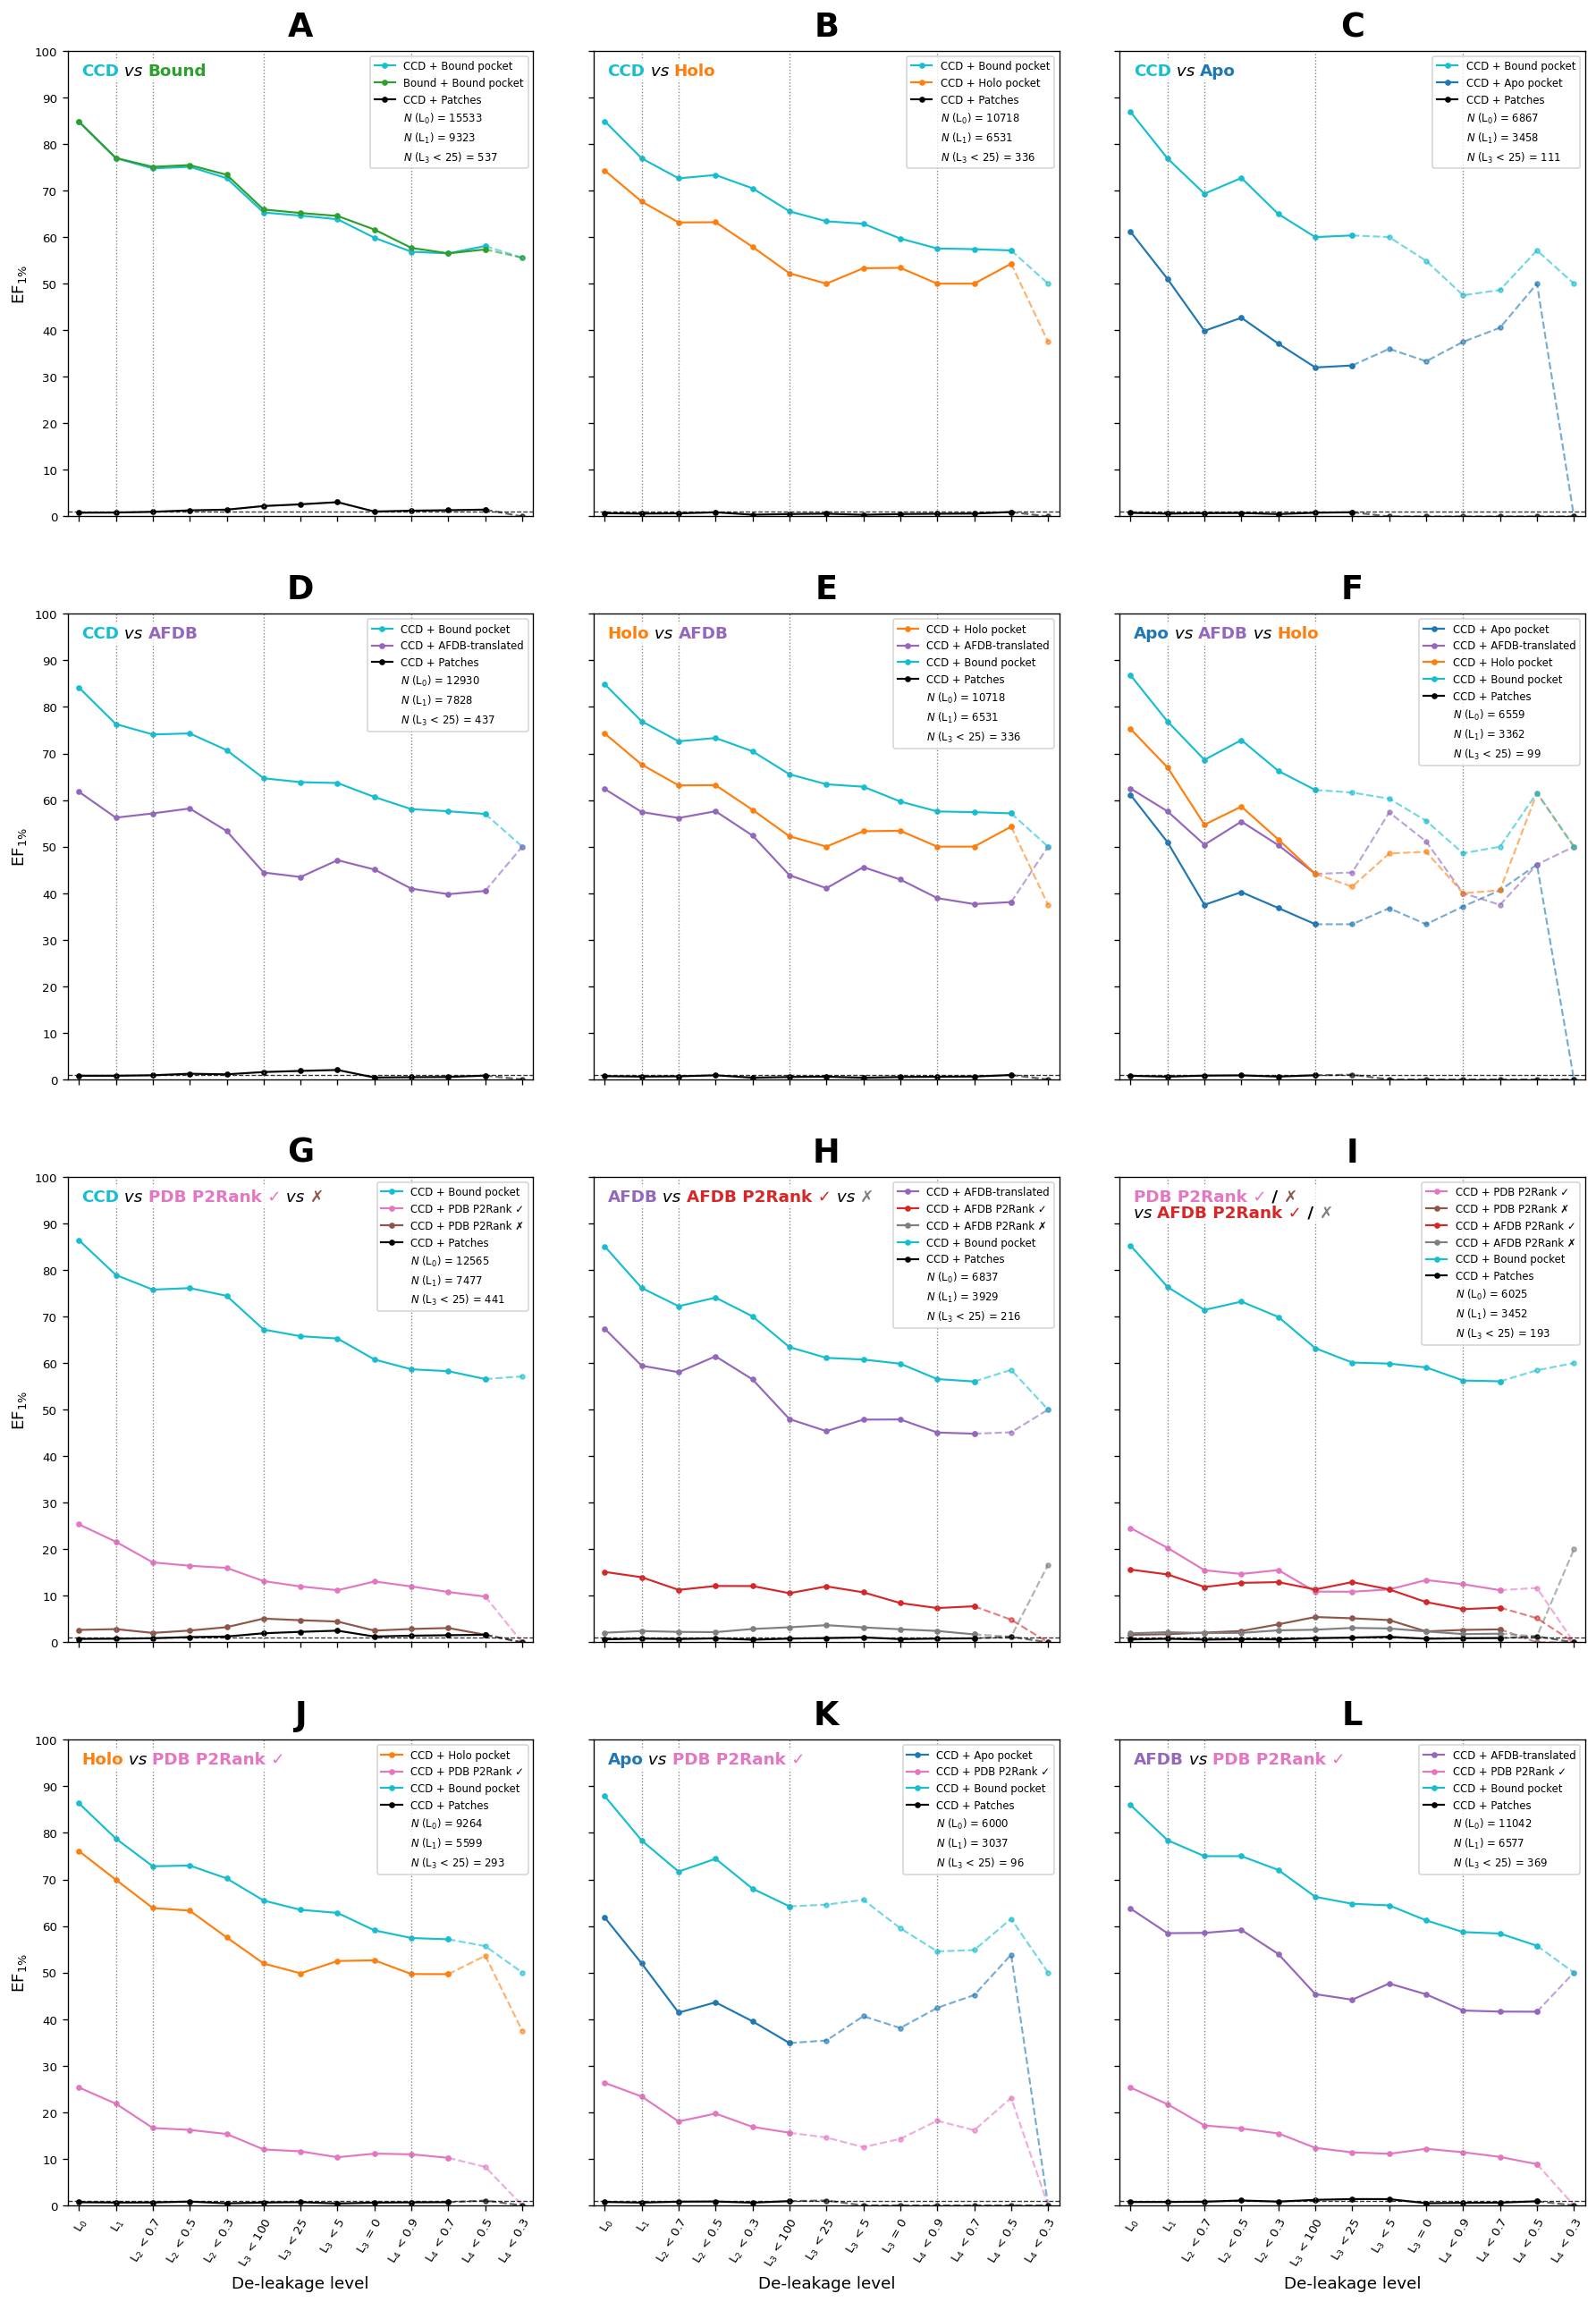

In [8]:
def fmt_n(n: int) -> str:
    # thousands separator only for numbers with more than 5 digits
    return f'{n:,}' if abs(n) >= 100_000 else str(n)


DE_STAGES = [('L1', 'PDB de-leak       '), ('L2<0.7', 'Receptor de-leak       '),
             ('L3<100', 'Ligand frequency de-leak       '),
             ('L4<0.9', 'Ligand similarity de-leak       ')]


def draw_ladder(ax, name, small=False):
    conds, dfs = comp_data[name]
    n = n_table.loc[name].to_numpy()
    reliable = np.where(n >= MIN_RELIABLE_N)[0]
    k = reliable.max() if len(reliable) else 0
    x = np.arange(len(DE_LEVELS))
    for c in conds:
        y = ef_table.loc[(name, COND_LABEL[c])].to_numpy(dtype=float)
        kw = dict(marker='o', ms=3 if small else 5, lw=1.3 if small else 1.6, color=COND_COLOUR[c])
        ax.plot(x[:k + 1], y[:k + 1], label=COND_LABEL[c], **kw)
        ax.plot(x[k:], y[k:], ls='--', alpha=0.6, **kw)
    ax.set_xticks(x)
    ax.set_xticklabels(DE_LEVELS_FMT, rotation=30 if not small else 60, ha='right',
                       rotation_mode='anchor', fontsize=13 if not small else 8)
    ax.set_xlim(x[0] - 0.3, x[-1] + 0.3)
    ax.set_yticks(range(0, 101, 10)); ax.set_ylim(0, 100)
    ax.set_box_aspect(1)
    for lv, txt in DE_STAGES:
        ax.axvline(DE_LEVELS.index(lv), color='grey', lw=0.8, ls=':')
        if not small:
            ax.annotate(txt, (DE_LEVELS.index(lv) + 0.1, 100), fontsize=10, color='grey',
                        rotation=90, va='top', ha='left')
    ax.axhline(1.0, ls='--', lw=0.8, color='black', alpha=0.8)
    if small:
        ax.tick_params(axis='y', labelsize=8)


from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.transforms import Bbox

# Panel titles, drawn top-left inside each panel. Each segment is (text, condition);
# condition=None -> black, '\n' starts a new line. Keyed by the COMPARISONS name.
_S, _B, _H, _A, _F = 'source_ccd', 'bound_bound', 'holo_ccd', 'apo_ccd', 'afdb_translated_ccd'
_PC, _PW = 'pdb_p2rank_correct_ccd', 'pdb_p2rank_wrong_ccd'
_AC, _AW = 'afdb_p2rank_correct_ccd', 'afdb_p2rank_wrong_ccd'
_VS = (' vs ', None)
TITLE_SEGMENTS = {
    'CCD vs Bound':                [('CCD', _S), _VS, ('Bound', _B)],
    'CCD vs Holo':                 [('CCD', _S), _VS, ('Holo', _H)],
    'CCD vs Apo':                  [('CCD', _S), _VS, ('Apo', _A)],
    'CCD vs AFDB':                 [('CCD', _S), _VS, ('AFDB', _F)],
    'Holo vs AFDB':                [('Holo', _H), _VS, ('AFDB', _F)],
    'Apo vs AFDB vs Holo':         [('Apo', _A), _VS, ('AFDB', _F), _VS, ('Holo', _H)],
    'CCD vs PDB P2Rank ✓ vs ✗':    [('CCD', _S), _VS, ('PDB P2Rank ✓', _PC), _VS, ('✗', _PW)],
    'AFDB vs AFDB P2Rank ✓ vs ✗':  [('AFDB', _F), _VS, ('AFDB P2Rank ✓', _AC), _VS, ('✗', _AW)],
    'PDB vs AFDB P2Rank ✓ / ✗':    [('PDB P2Rank ✓', _PC), (' / ', None), ('✗', _PW), ('\n', None),
                                    ('vs ', None), ('AFDB P2Rank ✓', _AC), (' / ', None), ('✗', _AW)],
    'Holo vs PDB P2Rank ✓':        [('Holo', _H), _VS, ('PDB P2Rank ✓', _PC)],
    'Apo vs PDB P2Rank ✓':         [('Apo', _A), _VS, ('PDB P2Rank ✓', _PC)],
    'AFDB vs PDB P2Rank ✓':        [('AFDB', _F), _VS, ('PDB P2Rank ✓', _PC)],
}


def draw_title(ax, segments, fontsize=11):
    # multi-coloured text: each segment is anchored to the right edge of the previous one.
    # Condition names bold in their line colour; 'vs' italic, regular weight. Returns the text artists.
    texts, line_start, prev = [], None, None
    for txt, cond in segments:
        if txt == '\n':
            prev = None
            continue
        is_vs = txt.strip() == 'vs'
        kw = dict(fontsize=fontsize, zorder=6,
                  fontweight='normal' if is_vs else 'bold',
                  fontstyle='italic' if is_vs else 'normal',
                  color=COND_COLOUR[cond] if cond else 'black')
        if line_start is None:
            prev = ax.annotate(txt, xy=(0.03, 0.975), xycoords='axes fraction', va='top', ha='left', **kw)
            line_start = prev
        elif prev is None:   # first segment of a new line: below the previous line's start
            prev = ax.annotate(txt, xy=(0, 0), xycoords=line_start, va='top', ha='left', **kw)
            line_start = prev
        else:
            prev = ax.annotate(txt, xy=(1, 0), xycoords=prev, va='bottom', ha='left', **kw)
        texts.append(prev)
    return texts


def add_title_box(ax, texts, pad_px=4):
    # one borderless white box (75% opaque) behind all title segments; call after the final layout
    renderer = ax.figure.canvas.get_renderer()
    bb = Bbox.union([t.get_window_extent(renderer) for t in texts]).padded(pad_px)
    (x0, y0), (x1, y1) = ax.transAxes.inverted().transform(bb.get_points())
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, transform=ax.transAxes,
                           facecolor='white', alpha=0.75, edgecolor='none', zorder=5.5))


GRID_COLS = 3
grid_rows = -(-len(COMPARISONS) // GRID_COLS)
fig, axes = plt.subplots(grid_rows, GRID_COLS, figsize=(5.0 * GRID_COLS, 5.4 * grid_rows), squeeze=False)
title_texts = {}
for i, (ax, (name, _)) in enumerate(zip(axes.flat, COMPARISONS)):
    draw_ladder(ax, name, small=True)
    ax.set_title(chr(ord('A') + i), fontsize=22, fontweight='bold', pad=10)
    title_texts[ax] = draw_title(ax, TITLE_SEGMENTS[name])
    # N per level as extra (handle-less) legend rows under the condition entries, same box
    handles, labels = ax.get_legend_handles_labels()
    nl = n_table.loc[name]
    for lv in ('L0', 'L1', 'L3<25'):
        handles.append(Line2D([], [], linestyle='none'))
        labels.append(f'$N$ ({format_level_label(lv)}) = {fmt_n(nl[lv])}')
    ax.legend(handles, labels, fontsize=7, loc='upper right')
for ax in axes.flat[len(COMPARISONS):]:
    ax.axis('off')
# tick labels only on the outer panels: y on the left column, x on the bottom panel of each column
n_panels = len(COMPARISONS)
for i, ax in enumerate(axes.flat[:n_panels]):
    if i % GRID_COLS:
        ax.tick_params(axis='y', labelleft=False)
    if i + GRID_COLS < n_panels:
        ax.tick_params(axis='x', labelbottom=False)
    else:
        ax.set_xlabel('De-leakage level', fontsize=11)
for ax in axes[:, 0]:
    ax.set_ylabel(r'EF$_{1\%}$', fontsize=11)
# same figure size, extra padding between panels -> each panel a bit smaller, less crowded
fig.tight_layout(w_pad=3.5, h_pad=3.0)
for ax, texts in title_texts.items():
    add_title_box(ax, texts)
fig.savefig(BENCH / 'fig56_ef1pct_vs_deleak_grid.png', dpi=600, bbox_inches='tight')
plt.show()

In [9]:
for i, (name, _) in enumerate(COMPARISONS, start=1):
    fig, ax = plt.subplots(figsize=(8, 8))
    draw_ladder(ax, name)
    ax.set_ylabel(r'EF$_{1\%}$', fontsize=13); ax.set_xlabel('De-leakage level', fontsize=13)
    if SHOW_TITLES_LEGENDS:
        ax.set_title(f'{name} (common pockets of this comparison)')
        ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
    ax.set_box_aspect(1)
    fig.tight_layout()
    fig.savefig(BENCH / f'fig56_ef1pct_vs_deleak_{i:02d}.png', dpi=600, bbox_inches='tight')
    plt.close(fig)
    print(f'fig56_ef1pct_vs_deleak_{i:02d}.png  <-  {name}')

fig56_ef1pct_vs_deleak_01.png  <-  CCD vs Bound


fig56_ef1pct_vs_deleak_02.png  <-  CCD vs Holo


fig56_ef1pct_vs_deleak_03.png  <-  CCD vs Apo


fig56_ef1pct_vs_deleak_04.png  <-  CCD vs AFDB


fig56_ef1pct_vs_deleak_05.png  <-  Holo vs AFDB


fig56_ef1pct_vs_deleak_06.png  <-  Apo vs AFDB vs Holo


... (2 outputs left out)

fig56_ef1pct_vs_deleak_09.png  <-  PDB vs AFDB P2Rank ✓ / ✗


fig56_ef1pct_vs_deleak_10.png  <-  Holo vs PDB P2Rank ✓


fig56_ef1pct_vs_deleak_11.png  <-  Apo vs PDB P2Rank ✓


fig56_ef1pct_vs_deleak_12.png  <-  AFDB vs PDB P2Rank ✓


## EF@1% values behind the curves

In [10]:
ef_table.round(1)

level                                               L0    L1  L2<0.7  L2<0.5  \
comparison                 condition                                           
CCD vs Bound               CCD + Bound pocket     84.8  77.0    74.7    75.1   
                           Bound + Bound pocket   84.8  77.0    75.1    75.5   
                           CCD + Patches           0.8   0.8     1.0     1.3   
CCD vs Holo                CCD + Bound pocket     84.9  76.9    72.6    73.3   
                           CCD + Patches           0.7   0.6     0.7     0.9   
                           CCD + Holo pocket      74.3  67.6    63.1    63.2   
CCD vs Apo                 CCD + Bound pocket     86.9  76.9    69.3    72.7   
                           CCD + Patches           0.8   0.6     0.7     0.7   
                           CCD + Apo pocket       61.2  51.0    39.9    42.7   
CCD vs AFDB                CCD + Bound pocket     84.2  76.3    74.1    74.3   
                           CCD + Patches           0.8   0.8     0.9     1.2   
                           CCD + AFDB-translated  61.8  56.2    57.1    58.2   
Holo vs AFDB               CCD + Bound pocket     84.9  76.9    72.6    73.3   
                           CCD + Patches           0.7   0.6     0.7     0.9   
                           CCD + Holo pocket      74.3  67.6    63.1    63.2   
                           CCD + AFDB-translated  62.4  57.4    56.2    57.6   
Apo vs AFDB vs Holo        CCD + Bound pocket     86.8  76.9    68.6    72.9   
                           CCD + Patches           0.8   0.6     0.8     0.9   
                           CCD + Holo pocket      75.3  67.0    54.7    58.6   
                           CCD + Apo pocket       61.1  51.0    37.5    40.2   
                           CCD + AFDB-translated  62.5  57.6    50.4    55.4   
CCD vs PDB P2Rank ✓ vs ✗   CCD + Bound pocket     86.4  78.9    75.8    76.1   
                           CCD + Patches           0.7   0.8     0.9     1.1   
                           CCD + PDB P2Rank ✓     25.4  21.6    17.2    16.5   
                           CCD + PDB P2Rank ✗      2.7   2.8     2.0     2.5   
AFDB vs AFDB P2Rank ✓ vs ✗ CCD + Bound pocket     85.1  76.1    72.2    74.0   
                           CCD + Patches           0.7   0.8     0.7     0.9   
                           CCD + AFDB-translated  67.4  59.4    58.0    61.4   
                           CCD + AFDB P2Rank ✓    15.1  14.0    11.3    12.1   
                           CCD + AFDB P2Rank ✗     2.1   2.4     2.3     2.2   
PDB vs AFDB P2Rank ✓ / ✗   CCD + Bound pocket     85.2  76.3    71.4    73.2   
                           CCD + Patches           0.6   0.8     0.6     0.7   
                           CCD + PDB P2Rank ✓     24.6  20.3    15.5    14.7   
                           CCD + PDB P2Rank ✗      1.6   1.8     2.1     2.4   
                           CCD + AFDB P2Rank ✓    15.6  14.6    11.9    12.8   
                           CCD + AFDB P2Rank ✗     1.9   2.2     2.0     2.0   
Holo vs PDB P2Rank ✓       CCD + Bound pocket     86.4  78.8    72.8    73.0   
                           CCD + Patches           0.7   0.6     0.6     0.8   
                           CCD + Holo pocket      76.1  69.9    63.9    63.3   
                           CCD + PDB P2Rank ✓     25.3  21.8    16.6    16.2   
Apo vs PDB P2Rank ✓        CCD + Bound pocket     87.9  78.4    71.7    74.4   
                           CCD + Patches           0.7   0.6     0.8     0.8   
                           CCD + Apo pocket       61.8  52.0    41.4    43.6   
                           CCD + PDB P2Rank ✓     26.3  23.4    18.0    19.7   
AFDB vs PDB P2Rank ✓       CCD + Bound pocket     86.0  78.4    75.0    75.0   
                           CCD + Patches           0.7   0.7     0.8     1.1   
                           CCD + AFDB-translated  63.7  58.5    58.5    59.2   
                           CCD + PDB P2Rank ✓     25.3  21.7    17.2    16.5   


---
## Notes

* **Figures in `RESULTS/benchmark/`:** `fig56_ef1pct_vs_deleak_grid.png` (all comparisons), plus one `fig56_ef1pct_vs_deleak_<nn>.png` per comparison, numbered in `COMPARISONS` order. Titles and legends on the single figures follow `SHOW_TITLES_LEGENDS`, as in nb52.
* **To add or change a comparison**, edit `COMPARISONS`. The set intersection, tables and figures all follow from it.